In [1]:
from google.colab import files

uploaded = files.upload()

Saving titanic_cleaned.csv to titanic_cleaned.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv("titanic_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (778, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,False,3,male,22.0,1,0,7.2500,S,third,man,True,unknown,southampton,False,False
1,True,1,female,38.0,1,0,71.2833,C,first,woman,False,c,cherbourg,True,False
2,True,3,female,26.0,0,0,7.9250,S,third,woman,False,unknown,southampton,True,True
3,True,1,female,35.0,1,0,53.1000,S,first,woman,False,c,southampton,True,False
4,False,3,male,35.0,0,0,8.0500,S,third,man,True,unknown,southampton,False,True


In [3]:
# Basic dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (778, 15)

Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 778 entries, 0 to 777
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     778 non-null    bool   
 1   pclass       778 non-null    int64  
 2   sex          778 non-null    object 
 3   age          778 non-null    float64
 4   sibsp        778 non-null    int64  
 5   parch        778 non-null    int64  
 6   fare         778 non-null    float64
 7   embarked     778 non-null    object 
 8   class        778 non-null    object 
 9   who          778 non-null    object 
 10  adult_male   778 non-null    bool   
 11  deck         778 non-null    object 
 12  embark_town  778 non-null    object 
 13  alive        778 non-null    bool   
 14  alone     

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0



Duplicate Rows:
0


In [4]:
# Statistical summary of numerical columns

print("NUMERICAL DATA SUMMARY")

display(df.describe())

print("\nCATEGORICAL DATA SUMMARY")

display(df.describe(include="object"))

NUMERICAL DATA SUMMARY


,pclass,age,sibsp,parch,fare
count,778.000000,778.000000,778.000000,778.000000,778.000000
mean,2.242931,29.622648,0.526992,0.419023,34.905993
std,0.854307,14.000755,0.988956,0.839346,52.308564
min,1.000000,0.420000,0.000000,0.000000,0.000000
25%,1.000000,21.125000,0.000000,0.000000,8.050000
50%,3.000000,28.000000,0.000000,0.000000,16.050000
75%,3.000000,38.000000,1.000000,1.000000,34.375000
max,3.000000,80.000000,8.000000,6.000000,512.329200



CATEGORICAL DATA SUMMARY


,sex,embarked,class,who,deck,embark_town
count,778,778,778,778,778,778
unique,2,3,3,3,8,3
top,male,S,third,man,unknown,southampton
freq,485,566,401,445,577,566


Survival Count:
survived
False    455
True     323
Name: count, dtype: int64


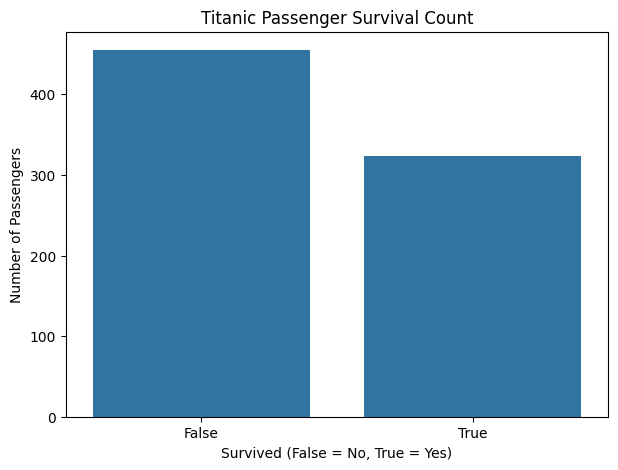

In [5]:
# Survival count

survival_counts = df["survived"].value_counts()

print("Survival Count:")
print(survival_counts)

# Create bar chart

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="survived")

plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survived (False = No, True = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

Gender-wise Survival Percentage:


survived,False,True
sex,,
female,25.94,74.06
male,78.14,21.86


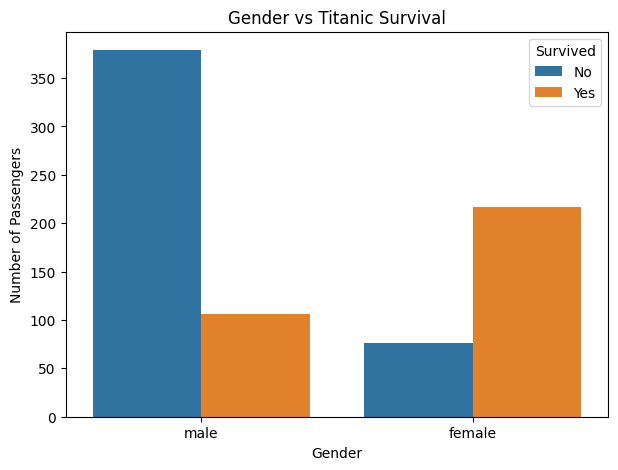

In [6]:
# Gender vs Survival

gender_survival = pd.crosstab(
    df["sex"],
    df["survived"],
    normalize="index"
) * 100

print("Gender-wise Survival Percentage:")
display(gender_survival.round(2))

# Create chart

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sex", hue="survived")

plt.title("Gender vs Titanic Survival")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])

plt.show()

Class-wise Survival Percentage:


survived,False,True
class,,
first,36.32,63.68
second,49.09,50.91
third,74.06,25.94


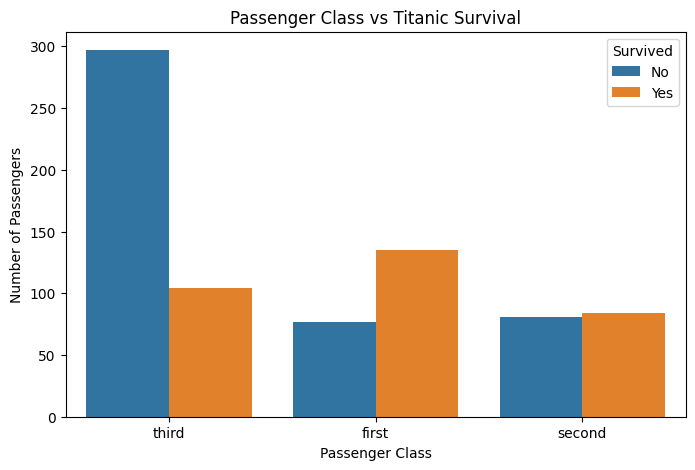

In [7]:
# Passenger Class vs Survival

class_survival = pd.crosstab(
    df["class"],
    df["survived"],
    normalize="index"
) * 100

print("Class-wise Survival Percentage:")
display(class_survival.round(2))

# Create chart

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="class", hue="survived")

plt.title("Passenger Class vs Titanic Survival")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])

plt.show()

Age Statistics:
Average Age: 29.62
Youngest Passenger: 0.42
Oldest Passenger: 80.0


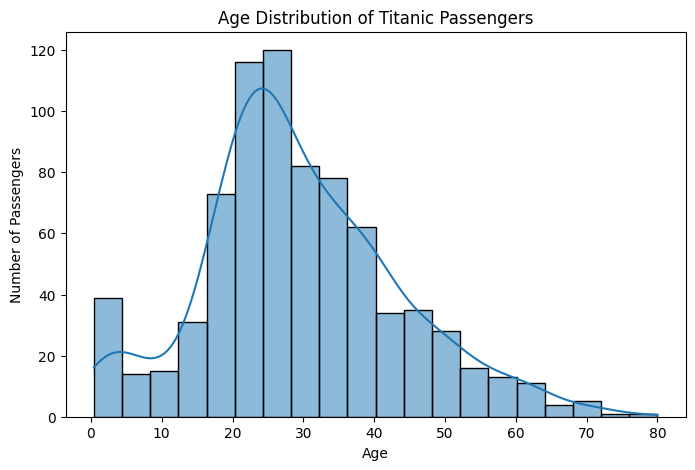

In [9]:
# Age Distribution

print("Age Statistics:")
print("Average Age:", round(df["age"].mean(), 2))
print("Youngest Passenger:", df["age"].min())
print("Oldest Passenger:", df["age"].max())

# Create histogram

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

In [10]:
# Create Age Groups

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 60, 100],
    labels=["Child", "Teenager", "Adult", "Senior"]
)

print("Age Group Counts:")
display(df["age_group"].value_counts())

Age Group Counts:


,count
age_group,
Adult,621
Child,68
Teenager,67
Senior,22


Age Group-wise Survival Percentage:


survived,False,True
age_group,,
Child,42.65,57.35
Teenager,55.22,44.78
Adult,59.90,40.10
Senior,77.27,22.73


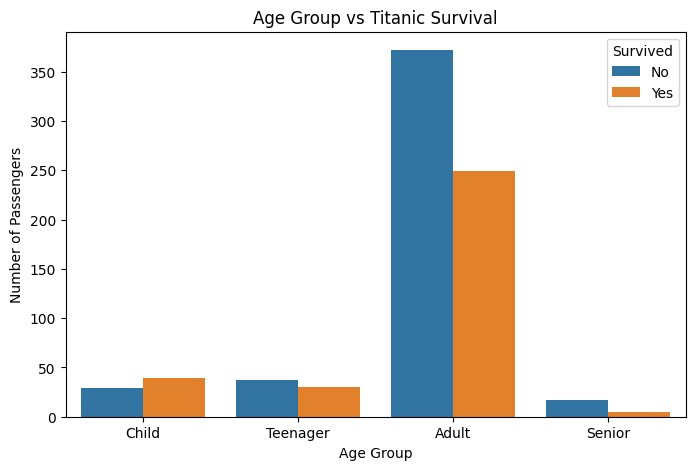

In [11]:
# Age Group vs Survival Percentage

age_survival = pd.crosstab(
    df["age_group"],
    df["survived"],
    normalize="index"
) * 100

print("Age Group-wise Survival Percentage:")
display(age_survival.round(2))

# Create chart

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="age_group", hue="survived")

plt.title("Age Group vs Titanic Survival")
plt.xlabel("Age Group")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])

plt.show()

Fare Statistics:
Average Fare: 34.91
Median Fare: 16.05
Minimum Fare: 0.0
Maximum Fare: 512.3292


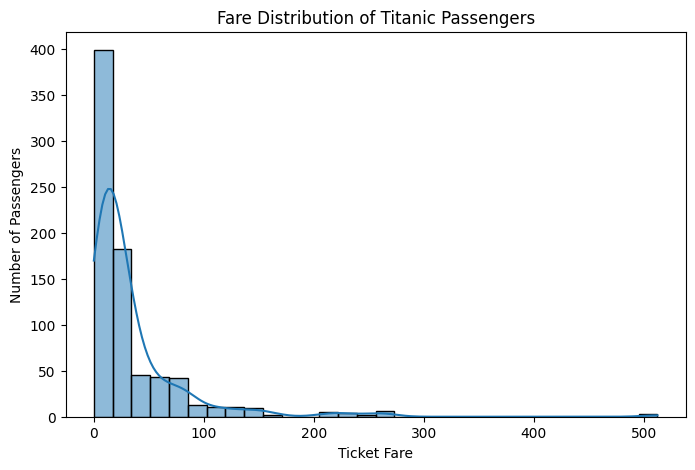

In [12]:
# Fare Statistics

print("Fare Statistics:")
print("Average Fare:", round(df["fare"].mean(), 2))
print("Median Fare:", round(df["fare"].median(), 2))
print("Minimum Fare:", df["fare"].min())
print("Maximum Fare:", df["fare"].max())

# Fare Distribution

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="fare", bins=30, kde=True)

plt.title("Fare Distribution of Titanic Passengers")
plt.xlabel("Ticket Fare")
plt.ylabel("Number of Passengers")

plt.show()

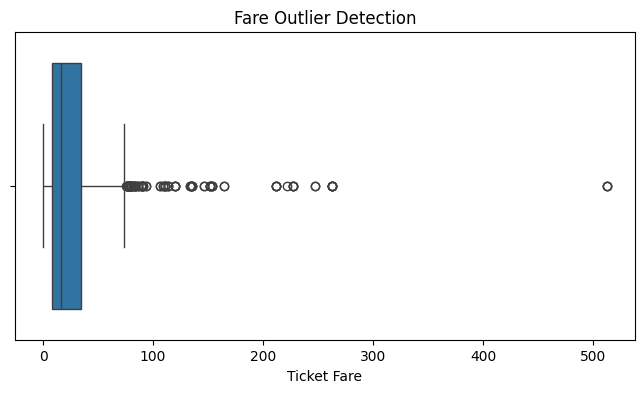

In [13]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x="fare")

plt.title("Fare Outlier Detection")
plt.xlabel("Ticket Fare")

plt.show()

In [14]:
# Calculate Family Size

df["family_size"] = df["sibsp"] + df["parch"] + 1

print("Family Size Summary:")
display(df["family_size"].describe())

print("\nFamily Size Counts:")
display(df["family_size"].value_counts().sort_index())

Family Size Summary:


,family_size
count,778.000000
mean,1.946015
std,1.521080
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,11.000000



Family Size Counts:


,count
family_size,
1,440
2,154
3,101
4,28
5,13
6,22
7,12
8,6
11,2


Family Size-wise Survival Percentage:


survived,False,True
family_size,,
1,65.91,34.09
2,44.81,55.19
3,42.57,57.43
4,28.57,71.43
5,76.92,23.08
6,86.36,13.64
7,66.67,33.33
8,100.00,0.00
11,100.00,0.00


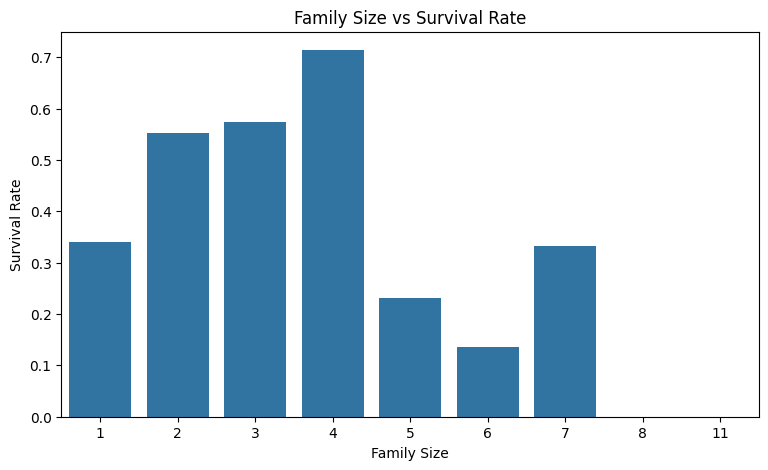

In [16]:
# Family Size vs Survival

family_survival = pd.crosstab(
    df["family_size"],
    df["survived"],
    normalize="index"
) * 100

print("Family Size-wise Survival Percentage:")
display(family_survival.round(2))

# Create chart

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="family_size",
    y="survived",
    errorbar=None
)

plt.title("Family Size vs Survival Rate")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate")

plt.show()

Port-wise Survival Percentage:


survived,False,True
embark_town,,
cherbourg,41.18,58.82
queenstown,66.10,33.90
southampton,62.37,37.63


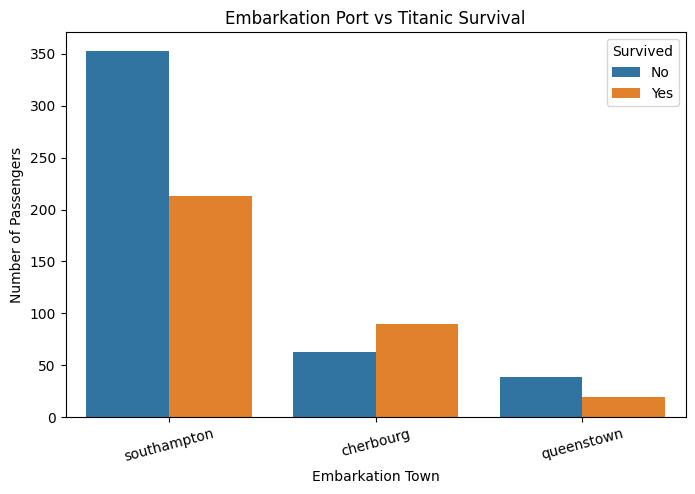

In [17]:
# Embarkation Port vs Survival

port_survival = pd.crosstab(
    df["embark_town"],
    df["survived"],
    normalize="index"
) * 100

print("Port-wise Survival Percentage:")
display(port_survival.round(2))

# Create chart

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="embark_town", hue="survived")

plt.title("Embarkation Port vs Titanic Survival")
plt.xlabel("Embarkation Town")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=15)
plt.legend(title="Survived", labels=["No", "Yes"])

plt.show()

Correlation Matrix:


,pclass,age,sibsp,parch,fare,family_size
pclass,1.00,-0.40,0.09,0.04,-0.55,0.08
age,-0.40,1.00,-0.29,-0.19,0.11,-0.29
sibsp,0.09,-0.29,1.00,0.38,0.13,0.86
parch,0.04,-0.19,0.38,1.00,0.19,0.80
fare,-0.55,0.11,0.13,0.19,1.00,0.19
family_size,0.08,-0.29,0.86,0.80,0.19,1.00


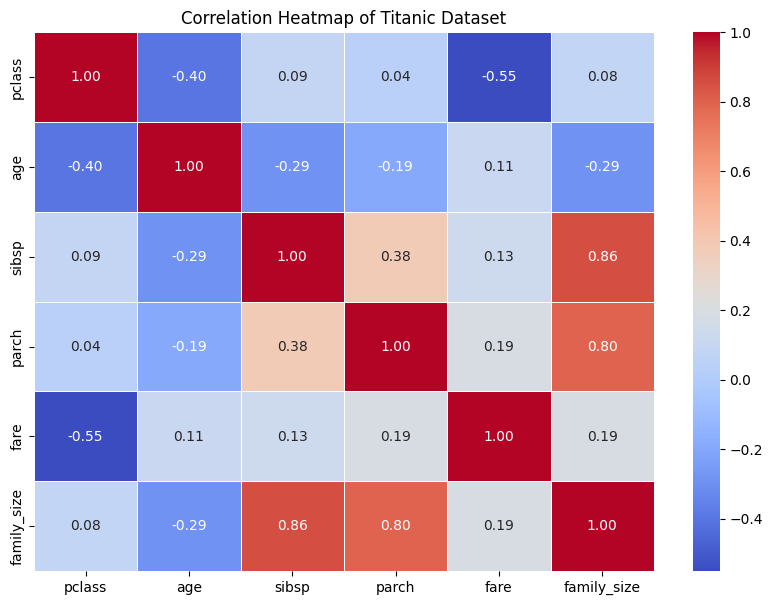

In [18]:
# Select numerical columns

numeric_df = df.select_dtypes(include=["number"])

# Calculate correlation

correlation = numeric_df.corr()

print("Correlation Matrix:")
display(correlation.round(2))

# Create heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Titanic Dataset")
plt.show()

In [19]:
# Overall Survival Rate

overall_survival = df["survived"].mean() * 100

print("OVERALL SURVIVAL RATE:", round(overall_survival, 2), "%")

# Gender-wise Survival Rate

print("\n1. GENDER-WISE SURVIVAL RATE")
display(
    (df.groupby("sex")["survived"].mean() * 100).round(2)
)

# Class-wise Survival Rate

print("\n2. CLASS-WISE SURVIVAL RATE")
display(
    (df.groupby("class")["survived"].mean() * 100).round(2)
)

# Age Group-wise Survival Rate

print("\n3. AGE GROUP-WISE SURVIVAL RATE")
display(
    (df.groupby("age_group", observed=False)["survived"].mean() * 100).round(2)
)

# Family Size-wise Survival Rate

print("\n4. FAMILY SIZE-WISE SURVIVAL RATE")
display(
    (df.groupby("family_size")["survived"].mean() * 100).round(2)
)

# Port-wise Survival Rate

print("\n5. EMBARKATION PORT-WISE SURVIVAL RATE")
display(
    (df.groupby("embark_town")["survived"].mean() * 100).round(2)
)

OVERALL SURVIVAL RATE: 41.52 %

1. GENDER-WISE SURVIVAL RATE


,survived
sex,
female,74.06
male,21.86



2. CLASS-WISE SURVIVAL RATE


,survived
class,
first,63.68
second,50.91
third,25.94



3. AGE GROUP-WISE SURVIVAL RATE


,survived
age_group,
Child,57.35
Teenager,44.78
Adult,40.10
Senior,22.73



4. FAMILY SIZE-WISE SURVIVAL RATE


,survived
family_size,
1,34.09
2,55.19
3,57.43
4,71.43
5,23.08
6,13.64
7,33.33
8,0.00
11,0.00



5. EMBARKATION PORT-WISE SURVIVAL RATE


,survived
embark_town,
cherbourg,58.82
queenstown,33.90
southampton,37.63


In [20]:
# Create EDA Report

report = """
SWYNEX TASK 2 - EXPLORATORY DATA ANALYSIS
Dataset: Titanic Cleaned Dataset

1. DATASET OVERVIEW
- Total Records: 778
- Total Columns: 15
- Missing Values: 0
- Duplicate Rows: 0

2. KEY STATISTICS
- Average Age: 29.62
- Average Fare: 34.91
- Overall Survival Rate: 41.52%

3. KEY INSIGHTS

1. Female passengers had a survival rate of 74.06%,
   compared to 21.86% for male passengers.

2. First-class passengers had the highest survival rate
   at 63.68%.

3. Third-class passengers had the lowest survival rate
   at 25.94%.

4. Children had a survival rate of 57.35%,
   higher than adults and senior passengers.

5. Passengers travelling in families of 2 to 4 members
   generally had higher survival rates than solo travellers.

4. CONCLUSION
The analysis shows that survival was associated with
gender, passenger class, age and family size.
These patterns describe the dataset and do not establish
causation.
"""

with open("eda_report.txt", "w") as file:
    file.write(report)

print("EDA Report created successfully!")

EDA Report created successfully!


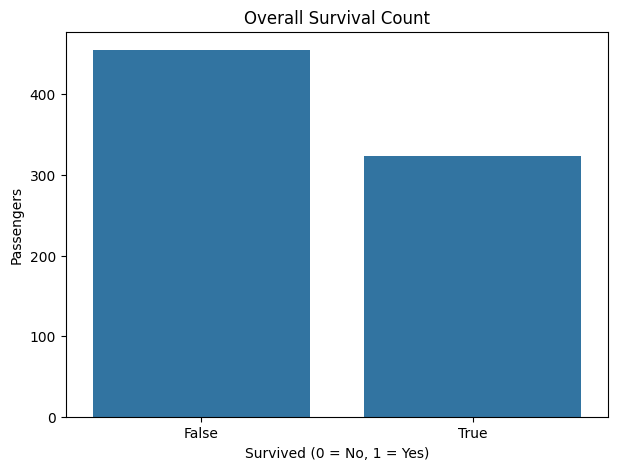

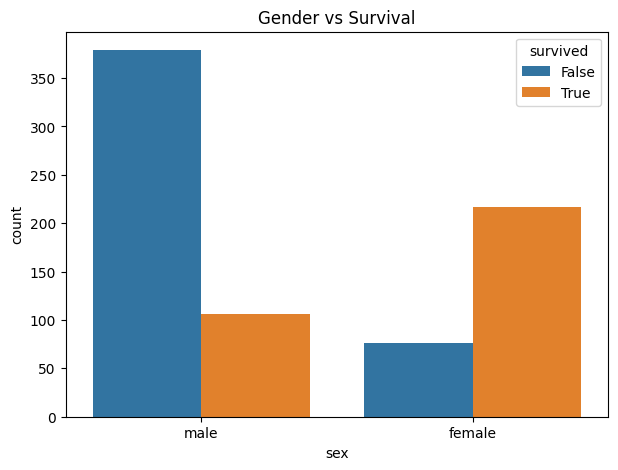

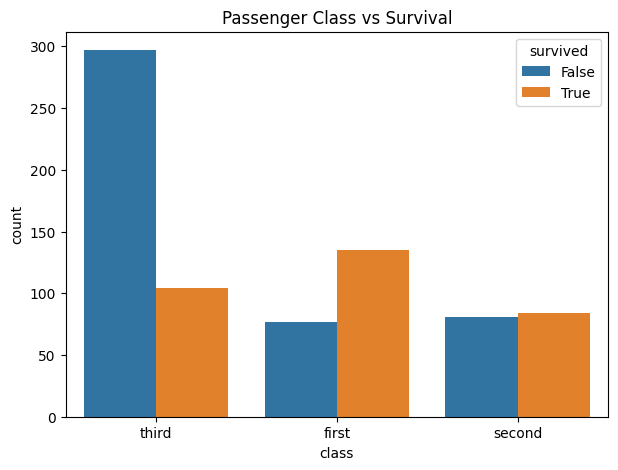

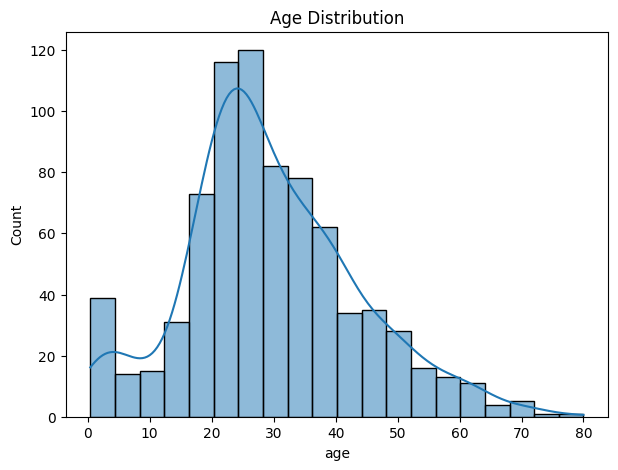

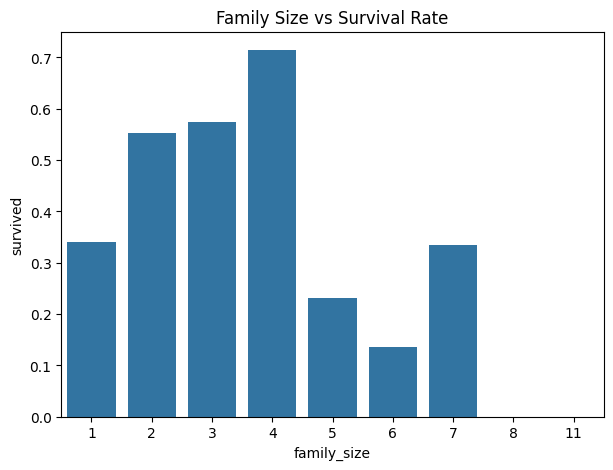

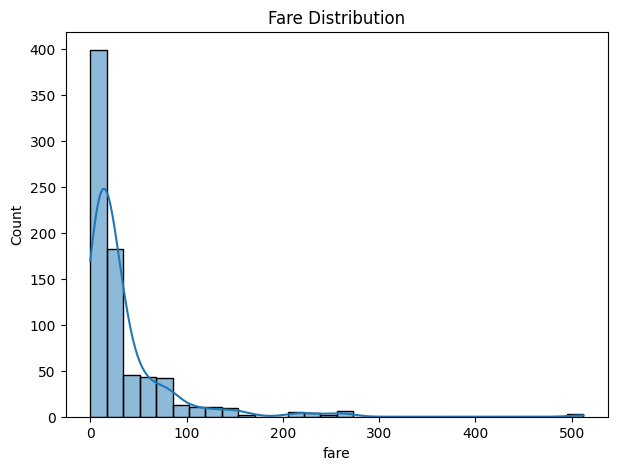

All 6 EDA charts saved successfully!


In [21]:
import os

# Create folder for charts
os.makedirs("eda_charts", exist_ok=True)

# 1. Overall Survival
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="survived")
plt.title("Overall Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Passengers")
plt.savefig("eda_charts/survival_count.png", bbox_inches="tight")
plt.show()

# 2. Gender vs Survival
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="sex", hue="survived")
plt.title("Gender vs Survival")
plt.savefig("eda_charts/gender_survival.png", bbox_inches="tight")
plt.show()

# 3. Class vs Survival
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="class", hue="survived")
plt.title("Passenger Class vs Survival")
plt.savefig("eda_charts/class_survival.png", bbox_inches="tight")
plt.show()

# 4. Age Distribution
plt.figure(figsize=(7, 5))
sns.histplot(data=df, x="age", bins=20, kde=True)
plt.title("Age Distribution")
plt.savefig("eda_charts/age_distribution.png", bbox_inches="tight")
plt.show()

# 5. Family Size vs Survival
plt.figure(figsize=(7, 5))
sns.barplot(data=df, x="family_size", y="survived", errorbar=None)
plt.title("Family Size vs Survival Rate")
plt.savefig("eda_charts/family_survival.png", bbox_inches="tight")
plt.show()

# 6. Fare Distribution
plt.figure(figsize=(7, 5))
sns.histplot(data=df, x="fare", bins=30, kde=True)
plt.title("Fare Distribution")
plt.savefig("eda_charts/fare_distribution.png", bbox_inches="tight")
plt.show()

print("All 6 EDA charts saved successfully!")

In [22]:
import shutil
from google.colab import files

# Create ZIP file containing all charts
shutil.make_archive("eda_charts", "zip", ".", "eda_charts")

# Download ZIP
files.download("eda_charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
from google.colab import files

files.download("eda_report.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>